# Orange – Algorytmy AI
## Zadanie szkoleniowe: Conv1D do regresji — ROZWIĄZANIE
### Prosta sieć neuronowa z warstwą Conv1D na zbiorze Pima Indians Diabetes

**Motyw przewodni.** Zbiór Pima zwykle służy do klasyfikacji. Tu robimy świadomy skręt dydaktyczny:
traktujemy dane jako problem **regresji** i przewidujemy poziom **glukozy** na podstawie pozostałych cech.
Conv1D jest narzędziem do pokazania, jak sieć uczy się lokalnych wzorców między uporządkowanymi cechami tabelarycznymi.

| Element | Opis |
|---|---|
| Czas | 60–75 minut |
| Poziom | Podstawowy plus: Python, pandas, ogólna idea sieci neuronowej |
| Biblioteki | pandas, numpy, scikit-learn, tensorflow/keras, matplotlib |
| Typ problemu | Regresja – predykcja wartości ciągłej |
| Architektura | Conv1D + pooling + warstwy Dense |
| Efekt końcowy | Działający notebook, metryki MAE/RMSE, krótka interpretacja |

### Wersja dla prowadzącego
- Wszystkie miejsca `TODO 1–3` są uzupełnione, `TODO 4` (interpretacja) jest napisany na podstawie wyników tego przebiegu.
- Sekcja 8 zawiera rozwiązania zadań dodatkowych D1–D6, każde uruchomione na 5 ziarnach losowości, z komentarzem do wyników.
- Sekcja 9 zawiera odpowiedzi na pytania kontrolne.
- Komórki **prawdzenie** zostały, żeby pokazać, jak wygląda poprawnie przechodzący notebook.
- Plik z danymi `pima.csv` powinien leżeć w tym samym katalogu co notebook. Pełne uruchomienie na CPU trwa ok. 10 minut (głównie sekcja 8).

> **Uwaga etyczna i metodologiczna.** Wyniku nie interpretujemy jako diagnozy. Dane medyczne wymagają walidacji
> klinicznej, kontroli biasu, zgód, bezpieczeństwa i audytu. Budujemy miniaturowy poligon treningowy,
> nie elektronicznego lekarza w pudełku.

## 1. Cel ćwiczenia
- Zrozumieć, jak przygotować dane tabelaryczne do wejścia warstwy Conv1D.
- Zbudować prostą sieć neuronową do regresji w Keras/TensorFlow.
- Porównać błąd modelu na danych treningowych i testowych.
- Zobaczyć, że Conv1D nie jest zarezerwowane dla tekstu i szeregów czasowych – choć w tabeli trzeba ostrożnie interpretować „sąsiedztwo” cech.
- Ocenić model regresyjny za pomocą MAE, MSE, RMSE i wykresu wartości rzeczywistych kontra przewidywanych.

## 2. Importy i ziarno losowości

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 3. Dane wejściowe

Zbiór Pima Indians Diabetes: **768 obserwacji, 9 kolumn**. Zmienną docelową jest `Glucose` (wartość ciągła), a nie `Outcome`.

| Kolumna | Znaczenie w ćwiczeniu |
|---|---|
| Pregnancies | Liczba ciąż – cecha wejściowa |
| **Glucose** | **Poziom glukozy – zmienna docelowa regresji** |
| BloodPressure | Ciśnienie krwi – cecha wejściowa |
| SkinThickness | Grubość fałdu skórnego – cecha wejściowa |
| Insulin | Poziom insuliny – cecha wejściowa |
| BMI | Wskaźnik masy ciała – cecha wejściowa |
| DiabetesPedigreeFunction | Funkcja obciążenia rodzinnego – cecha wejściowa |
| Age | Wiek – cecha wejściowa |
| Outcome | Etykieta klasyfikacyjna – w wersji podstawowej pomijamy |

### Krok 1. Wczytanie danych

In [ ]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

In [ ]:
# ROZWIĄZANIE TODO 1
# Plik w klasycznej wersji (UCI / repozytorium J. Brownlee) nie ma wiersza nagłówka,
# więc header=None, a nazwy kolumn podajemy listą `columns`.
# Dla wersji z Kaggle (z nagłówkiem): pd.read_csv("pima.csv", header=0, names=columns).
df = pd.read_csv("pima.csv", header=None, names=columns)

** Sprawdzenie**

In [ ]:
assert df is not None, "Zmienna df jest pusta – uzupełnij TODO 1."
assert df.shape == (768, 9), f"Oczekiwano (768, 9), jest {df.shape}. Sprawdź parametr header."
assert list(df.columns) == columns, "Nazwy kolumn nie zgadzają się z listą `columns`."
print("OK – dane wczytane poprawnie.")

OK – dane wczytane poprawnie.


### Krok 2. Rozmiar, typy kolumn i podstawowe statystyki

In [ ]:
print(df.shape)
display(df.head())
print(df.dtypes)
display(df.describe().T)

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### Krok 3. Zera jako braki danych

W kolumnach `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` wartość **0 jest medycznie nielogiczna** – traktujemy ją jako brak danych.

In [ ]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Liczba zer przed zamianą:")
print((df[zero_as_missing] == 0).sum())

df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

print("\nLiczba braków (NaN) po zamianie:")
print(df.isna().sum())

Liczba zer przed zamianą:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Liczba braków (NaN) po zamianie:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


### Kroki 4–6. Zmienna docelowa, macierz cech, podział train/test

- Usuwamy wiersze bez wartości docelowej `Glucose`.
- Braki w cechach wejściowych uzupełnimy **medianą liczoną tylko na zbiorze treningowym** (w kolejnym kroku – w pipeline).
- Podział 80/20.

In [ ]:
target_col = "Glucose"
feature_cols = [
    "Pregnancies", "BloodPressure", "SkinThickness", "Insulin",
    "BMI", "DiabetesPedigreeFunction", "Age"
]

df_model = df.dropna(subset=[target_col]).copy()
print("Wiersze po usunięciu braków w Glucose:", len(df_model))

X = df_model[feature_cols]
y = df_model[target_col].to_numpy().reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Wiersze po usunięciu braków w Glucose: 763
Train: (610, 7) Test: (153, 7)


### Krok 7. Imputacja i skalowanie

Pipeline dla X: imputacja medianą + standaryzacja. Uczymy go (`fit`) **tylko na zbiorze treningowym** – to chroni przed wyciekiem informacji ze zbioru testowego.
Skalujemy też `y`, żeby sieć uczyła się stabilniej.

In [ ]:
x_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_train_scaled = x_preprocess.fit_transform(X_train)
X_test_scaled = x_preprocess.transform(X_test)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

print("Średnia y_train_scaled:", round(float(y_train_scaled.mean()), 4),
      "| odchylenie:", round(float(y_train_scaled.std()), 4))

Średnia y_train_scaled: -0.0 | odchylenie: 1.0


### Krok 8. Tensor 3D dla Conv1D

Conv1D oczekuje kształtu **(próbki, kroki, kanały)**. Każda cecha staje się kolejnym „krokiem” krótkiej sekwencji, a kanał jest jeden.

In [ ]:
X_train_conv = X_train_scaled[..., np.newaxis]
X_test_conv = X_test_scaled[..., np.newaxis]

print("X_train_conv shape:", X_train_conv.shape)
print("X_test_conv shape:", X_test_conv.shape)

X_train_conv shape: (610, 7, 1)
X_test_conv shape: (153, 7, 1)


## 4. Architektura sieci

| Warstwa | Rola |
|---|---|
| Input | Tensor o kształcie (liczba cech, 1) – każda cecha to kolejny krok sekwencji |
| Conv1D | Małe lokalne filtry; `kernel_size=2` patrzy na pary sąsiednich cech |
| Conv1D | Druga warstwa buduje bardziej złożone reprezentacje |
| GlobalAveragePooling1D | Redukuje wymiar sekwencyjny do wektora |
| Dense | Łączy reprezentacje, transformacja nieliniowa |
| Dense(1) | Jedna liczba: przewidywana `Glucose` na skali standaryzowanej |

> **Uwaga.** Conv1D zakłada lokalność – sąsiednie pozycje mają znaczenie. W szeregach czasowych to naturalne,
> w tabeli medycznej kolejność cech jest **sztuczna**. Dlatego to ćwiczenie uczy mechaniki Conv1D,
> a w realnym projekcie trzeba je porównać z modelem Dense, Random Forest lub Gradient Boosting.

### Krok 9a. Budowa i kompilacja modelu

In [ ]:
# ROZWIĄZANIE TODO 2
# Kształty dla 7 cech: wejście (7, 1) -> Conv1D k=2 -> (6, 32) -> Conv1D k=2 -> (5, 16)
# -> GlobalAveragePooling1D -> (16,) -> Dense(16) -> Dense(1).
# Model jest celowo mały: mamy ~490 próbek treningowych (po odjęciu walidacji).
model = models.Sequential([
    layers.Input(shape=(X_train_conv.shape[1], 1)),
    layers.Conv1D(filters=32, kernel_size=2, activation="relu"),
    layers.Conv1D(filters=16, kernel_size=2, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)          # regresja: wyjście liniowe
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 6, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 16)          │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,425 (5.57 KB)

 Trainable params: 1,425 (5.57 KB)

 Non-trainable params: 0 (0.00 B)

** Sprawdzenie**

In [ ]:
assert model is not None, "Zmienna model jest pusta – uzupełnij TODO 2."
assert any(isinstance(l, layers.Conv1D) for l in model.layers), "Model nie zawiera warstwy Conv1D."
assert model.output_shape == (None, 1), f"Wyjście powinno mieć kształt (None, 1), jest {model.output_shape}."
assert model.optimizer is not None and model.loss is not None, "Model nie jest skompilowany."
print("OK – model zbudowany i skompilowany.")

OK – model zbudowany i skompilowany.


### Krok 9b. Trening

Callback `early_stop` zdefiniuj **pod tą nazwą** – używa go też model porównawczy Dense w sekcji 7.

In [ ]:
# ROZWIĄZANIE TODO 3
# EarlyStopping przerywa trening, gdy val_loss nie poprawia się przez 20 epok,
# i przywraca wagi z najlepszej epoki. validation_split=0.2 wydziela walidację
# z OSTATNICH 20% zbioru treningowego (Keras nie tasuje przed podziałem – tu dane
# są już przetasowane przez train_test_split, więc to bezpieczne).
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)
history = model.fit(
    X_train_conv, y_train_scaled,
    validation_split=0.2, epochs=200, batch_size=32,
    callbacks=[early_stop], verbose=0
)

** Sprawdzenie**

In [ ]:
assert history is not None, "Brak obiektu history – uzupełnij TODO 3."
assert "val_loss" in history.history, "Brak val_loss – czy ustawiłeś validation_split?"
assert early_stop is not None, "Zdefiniuj early_stop – przyda się w sekcji 7."
print(f"OK – trening zakończony po {len(history.history['loss'])} epokach.")

OK – trening zakończony po 45 epokach.


## 5. Ewaluacja

### Krok 10. MAE i RMSE na zbiorze testowym
Predykcje wracają z przestrzeni standaryzowanej do jednostek glukozy (`inverse_transform`), więc metryki są w mg/dl.
Dla porównania liczymy też „model naiwny”, który zawsze zwraca średnią z treningu – sieć powinna być od niego lepsza.

In [ ]:
y_pred_scaled = model.predict(X_test_conv, verbose=0)
y_pred = y_scaler.inverse_transform(y_pred_scaled)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

y_naive = np.full_like(y_test, y_train.mean(), dtype=float)
mae_naive = mean_absolute_error(y_test, y_naive)
rmse_naive = np.sqrt(mean_squared_error(y_test, y_naive))

print(f"Conv1D  MAE: {mae:.2f}  RMSE: {rmse:.2f}")
print(f"Naiwny  MAE: {mae_naive:.2f}  RMSE: {rmse_naive:.2f}  (zawsze średnia z train)")

Conv1D  MAE: 20.34  RMSE: 26.09
Naiwny  MAE: 24.36  RMSE: 30.40  (zawsze średnia z train)


### Porównanie błędu train vs test
Duża różnica na korzyść zbioru treningowego to sygnał overfittingu.

In [ ]:
y_pred_train = y_scaler.inverse_transform(model.predict(X_train_conv, verbose=0))
mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"Train MAE: {mae_train:.2f}  RMSE: {rmse_train:.2f}")
print(f"Test  MAE: {mae:.2f}  RMSE: {rmse:.2f}")

Train MAE: 21.01  RMSE: 26.82
Test  MAE: 20.34  RMSE: 26.09


### Krok 11. Krzywa uczenia oraz wartości rzeczywiste kontra predykcje

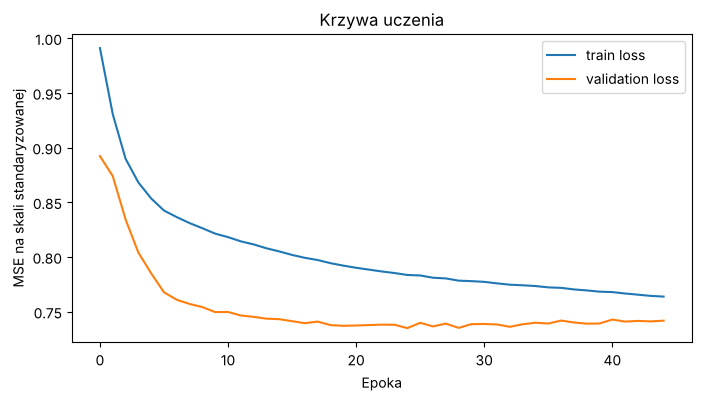

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoka")
plt.ylabel("MSE na skali standaryzowanej")
plt.legend()
plt.title("Krzywa uczenia")
plt.show()

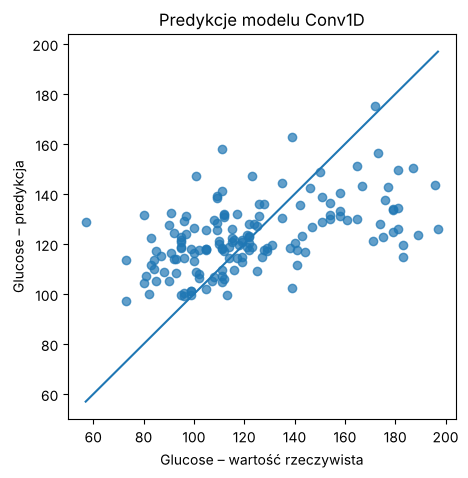

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.xlabel("Glucose – wartość rzeczywista")
plt.ylabel("Glucose – predykcja")
plt.title("Predykcje modelu Conv1D")
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims)
plt.show()

## 6. Interpretacja – rozwiązanie TODO 4

**Wyniki tego przebiegu:** Conv1D osiąga na teście **MAE ≈ 20,3 mg/dl i RMSE ≈ 26,1 mg/dl**, a model naiwny (zawsze średnia
z treningu) – MAE 24,4 i RMSE 30,4. Sieć jest więc lepsza od zgadywania średniej o ok. 16%, ale wyjaśnia tylko ok. 25% wariancji
glukozy (R² ≈ 0,25 w powtórzeniach z sekcji 8). Błąd na treningu (MAE 21,0) i teście (20,3) jest podobny, a krzywe uczenia
nie rozjeżdżają się – **nie ma overfittingu, jest raczej niedouczenie wynikające z ubogiej informacji w cechach.**

**Gdzie model się myli:** wykres rozrzutu pokazuje typową regresję do średniej. Predykcje mieszczą się w wąskim przedziale
ok. 100–175 mg/dl, więc pacjentki z wysoką glukozą (>160) są systematycznie **niedoszacowane** (nawet o 50–70 mg/dl),
a te z niską – **przeszacowane**. To najgorszy możliwy rozkład błędów dla zastosowania medycznego: model myli się najbardziej
właśnie w przypadkach klinicznie najważniejszych.

**Dlaczego tak:** najsilniej skorelowaną z glukozą cechą jest insulina (r ≈ 0,58), ale brakuje jej w 49% wierszy –
po imputacji medianą połowa pacjentek ma identyczną, sztuczną wartość i sygnał się rozmywa.

**Dlaczego Conv1D to tu demonstracja, a nie wybór produkcyjny:** kolejność kolumn w tabeli jest arbitralna, więc założenie
lokalności, na którym opiera się konwolucja, nie ma uzasadnienia w danych. Prosta sieć Dense z mniejszą liczbą parametrów
(801 vs 1425) daje ten sam albo nieco lepszy wynik (D3), a jakość Conv1D zależy od kolejności kolumn w pliku (D5).
W realnym projekcie punktem odniesienia byłby model Dense lub drzewiasty (Random Forest, Gradient Boosting).

> Uwaga: zbiór testowy ma tylko 153 obserwacje, a wynik pojedynczego treningu zależy od ziarna losowości.
> Różnice rzędu kilku dziesiątych mg/dl między wariantami mieszczą się w szumie – dlatego w sekcji 8 każdy wariant liczymy na kilku ziarnach.

## 7. Mini-wariant porównawczy: Dense baseline

Model kontrolny bez konwolucji. Celem nie jest pobicie Conv1D za wszelką cenę, tylko sprawdzenie,
czy konwolucja daje przewagę na tak małym zbiorze. Dense przyjmuje dane 2D – używamy `X_train_scaled`, nie `X_train_conv`.

In [ ]:
dense_model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])
dense_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
)
dense_history = dense_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

y_pred_dense_scaled = dense_model.predict(X_test_scaled, verbose=0)
y_pred_dense = y_scaler.inverse_transform(y_pred_dense_scaled)
mae_dense = mean_absolute_error(y_test, y_pred_dense)
rmse_dense = np.sqrt(mean_squared_error(y_test, y_pred_dense))

print(f"Conv1D  MAE: {mae:.2f}  RMSE: {rmse:.2f}")
print(f"Dense   MAE: {mae_dense:.2f}  RMSE: {rmse_dense:.2f}")

Conv1D  MAE: 20.34  RMSE: 26.09
Dense   MAE: 20.67  RMSE: 26.41


## 8. Zadania dodatkowe dla szybszych grup
Każde zadanie ma własną komórkę z `TODO`. Możesz skopiować i zmodyfikować kod z wcześniejszych sekcji.

### Funkcja pomocnicza do eksperymentów

Żeby zadania D1–D6 nie powtarzały kroków 4–10 w kółko, zamykamy cały pipeline w jednej funkcji.
**Podział train/test jest zawsze ten sam** (`random_state=SEED`), a parametr `seed` steruje tylko inicjalizacją wag
i kolejnością batchy. Dzięki temu różnice między wariantami wynikają z modelu, a nie z innego podziału danych.
Dla każdego wariantu robimy kilka uruchomień z różnymi ziarnami – pojedynczy przebieg sieci na 600 próbkach to za mało, żeby wyciągać wnioski.

In [ ]:
from sklearn.metrics import r2_score


def build_conv1d(n_features, kernel_size=2, regularization=None):
    """Conv1D z sekcji 4; opcjonalnie z Dropout albo BatchNormalization."""
    bn = regularization == "batchnorm"
    net = [layers.Input(shape=(n_features, 1)),
           layers.Conv1D(32, kernel_size, activation="relu")]
    if bn:
        net.append(layers.BatchNormalization())
    net.append(layers.Conv1D(16, kernel_size, activation="relu"))
    if bn:
        net.append(layers.BatchNormalization())
    net += [layers.GlobalAveragePooling1D(),
            layers.Dense(16, activation="relu")]
    if regularization == "dropout":
        net.append(layers.Dropout(0.2))
    net.append(layers.Dense(1))
    return models.Sequential(net)


def build_dense(n_features):
    """Dense baseline z sekcji 7."""
    return models.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])


def run_experiment(target, features, model_type="conv1d", kernel_size=2,
                   regularization=None, seed=SEED, data=df):
    """Pełny mini-pipeline: dane -> imputacja/skalowanie -> trening -> metryki na teście."""
    tf.keras.utils.set_random_seed(seed)

    d = data.dropna(subset=[target]).copy()
    X_ = d[list(features)]
    y_ = d[target].to_numpy().reshape(-1, 1)
    X_tr, X_te, y_tr, y_te = train_test_split(X_, y_, test_size=0.2, random_state=SEED)

    prep = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
    X_tr_s, X_te_s = prep.fit_transform(X_tr), prep.transform(X_te)
    ys = StandardScaler()
    y_tr_s = ys.fit_transform(y_tr)

    if model_type == "conv1d":
        m = build_conv1d(X_tr_s.shape[1], kernel_size, regularization)
        X_tr_in, X_te_in = X_tr_s[..., np.newaxis], X_te_s[..., np.newaxis]
    else:
        m = build_dense(X_tr_s.shape[1])
        X_tr_in, X_te_in = X_tr_s, X_te_s

    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse",
              metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")])
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                          restore_best_weights=True)
    h = m.fit(X_tr_in, y_tr_s, validation_split=0.2, epochs=200, batch_size=32,
              callbacks=[es], verbose=0)

    pred = ys.inverse_transform(m.predict(X_te_in, verbose=0))
    naive = np.full_like(y_te, y_tr.mean(), dtype=float)
    res = {
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R2": r2_score(y_te, pred),
        "MAE_naiwny": mean_absolute_error(y_te, naive),
        "epoki": len(h.history["loss"]),
    }
    res["poprawa_vs_naiwny_%"] = 100 * (1 - res["MAE"] / res["MAE_naiwny"])
    return res, h


def summarize(rows, by):
    """Średnia ± odchylenie metryk po kilku ziarnach."""
    t = pd.DataFrame(rows)
    return (t.groupby(by, sort=False)[["MAE", "RMSE", "R2", "poprawa_vs_naiwny_%"]]
             .agg(["mean", "std"]).round(2))


SEEDS = [0, 1, 2, 3, 4]

#### Wariant bazowy – liczony raz, używany w D1–D6
Conv1D z sekcji 4, cel `Glucose`, oryginalna kolejność cech, `kernel_size=2`, bez regularizacji – po 5 ziaren.
Ta sama konfiguracja jest punktem odniesienia w każdym zadaniu, więc nie trenujemy jej wielokrotnie.

In [ ]:
baseline_rows, baseline_hist = [], None
for s in SEEDS:
    r, h = run_experiment("Glucose", feature_cols, seed=s)
    baseline_rows.append(r)
    if s == SEEDS[0]:
        baseline_hist = h

def baseline(label_col, label):
    """Wyniki bazowe z dopisaną etykietą wariantu."""
    return [{label_col: label, **r} for r in baseline_rows]

pd.DataFrame(baseline_rows).round(2)

,MAE,RMSE,R2,MAE_naiwny,epoki,poprawa_vs_naiwny_%
0,20.80,26.50,0.24,24.36,93,14.64
1,20.70,26.34,0.25,24.36,86,15.05
2,21.07,26.57,0.24,24.36,81,13.51
3,20.64,26.00,0.27,24.36,84,15.31
4,20.34,26.19,0.26,24.36,58,16.53


### D1. Zmień target z `Glucose` na `BMI`. Czy model uczy się łatwiej czy trudniej?

In [ ]:
# D1: BMI jako cel, Glucose przechodzi do cech wejściowych.
features_bmi = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "DiabetesPedigreeFunction", "Age"]

rows = baseline("cel", "Glucose")
for s in SEEDS:
    r, _ = run_experiment("BMI", features_bmi, seed=s)
    rows.append({"cel": "BMI", **r})

d1 = summarize(rows, "cel")
d1

MAE         RMSE          R2       poprawa_vs_naiwny_%      
          mean   std   mean   std  mean   std                mean   std
cel                                                                    
Glucose  20.71  0.27  26.32  0.23  0.25  0.01               15.01  1.09
BMI       4.33  0.06   5.41  0.10  0.28  0.03               14.57  1.28

**Komentarz D1.** Surowych MAE (20,7 mg/dl vs 4,3 kg/m²) nie wolno porównywać – to różne jednostki i skale.
Porównujemy miary względne: R² (0,25 vs 0,28) i poprawę względem modelu naiwnego (15,0% vs 14,6%).
**Trudność jest podobna** – BMI ma nieco wyższe R², ale poprawa nad średnią jest praktycznie taka sama.
BMI ma jeden silny predyktor (grubość fałdu skórnego, r ≈ 0,65), ale tej cechy brakuje w ok. 30% wierszy,
więc – podobnie jak insulina dla glukozy – po imputacji traci dużą część sygnału.

### D2. Dodaj kolumnę `Outcome` jako cechę wejściową i sprawdź, czy wynik regresji się poprawia. Omów ryzyko interpretacyjne takiego wyboru.

In [ ]:
# D2: Outcome jako dodatkowa cecha wejściowa.
features_outcome = feature_cols + ["Outcome"]

rows = baseline("wariant", "bez Outcome")
for s in SEEDS:
    r, _ = run_experiment("Glucose", features_outcome, seed=s)
    rows.append({"wariant": "z Outcome", **r})

d2 = summarize(rows, "wariant")
d2

MAE         RMSE          R2       poprawa_vs_naiwny_%      
              mean   std   mean   std  mean   std                mean   std
wariant                                                                    
bez Outcome  20.71  0.27  26.32  0.23  0.25  0.01               15.01  1.09
z Outcome    20.59  0.27  25.71  0.11  0.28  0.01               15.49  1.12

**Komentarz D2.** Dodanie `Outcome` daje niewielką poprawę (R² 0,25 → 0,28, RMSE 26,3 → 25,7), ale **metodologicznie
jest to błąd – wyciek informacji (data leakage)**. W badaniu Pima cukrzycę rozpoznawano na podstawie testu obciążenia
glukozą, więc `Outcome` jest w dużej mierze funkcją samej zmiennej docelowej. W realnym scenariuszu diagnozy nie znamy
przed pomiarem glukozy – kolejność przyczynowa jest odwrócona. Model wyglądałby lepiej na teście, a w użyciu
nie miałby skąd wziąć tej cechy. Fakt, że zysk jest tu mały, nie zmienia zasady: **cechę ocenia się po tym, czy będzie
dostępna w momencie predykcji, a nie po tym, czy poprawia metrykę.**

### D3. Porównaj Conv1D z prostą siecią Dense bez konwolucji (sekcja 7).

In [ ]:
# D3: Conv1D vs Dense, po 5 ziaren. Model naiwny nie zależy od ziarna.
rows = baseline("model", "Conv1D")
for s in SEEDS:
    r, _ = run_experiment("Glucose", feature_cols, model_type="dense", seed=s)
    rows.append({"model": "Dense", **r})

d3 = summarize(rows, "model")
print(f"Model naiwny: MAE = {rows[0]['MAE_naiwny']:.2f}")
d3

Model naiwny: MAE = 24.36


MAE         RMSE          R2       poprawa_vs_naiwny_%      
         mean   std   mean   std  mean   std                mean   std
model                                                                 
Conv1D  20.71  0.27  26.32  0.23  0.25  0.01               15.01  1.09
Dense   20.29  0.33  25.99  0.51  0.27  0.03               16.70  1.34

**Komentarz D3.** Dense: MAE 20,29 ± 0,33, Conv1D: 20,71 ± 0,27 (średnia ± odchylenie po 5 ziarnach). Dense jest
**nieznacznie lepszy**, przy czym różnica (~0,4 mg/dl) jest niewiele większa od zmienności między ziarnami.
Dense ma przy tym mniej parametrów (801 vs 1425). Konwolucja nie daje więc żadnej przewagi na tych danych –
co jest oczekiwanym wynikiem dla tabeli bez naturalnej struktury sekwencyjnej.
Uczestnicy, którzy w sekcji 7 widzą odwrotny wynik (Conv1D lepszy przy SEED=42), dostają tu dobrą lekcję:
**jeden przebieg to nie dowód.**

### D4. Zmień `kernel_size` z 2 na 3. Co dzieje się z MAE i RMSE?

In [ ]:
# D4: kernel_size 2 vs 3. Przy 7 cechach: k=2 -> mapy 6 i 5 pozycji, k=3 -> 5 i 3 pozycje.
rows = baseline("kernel_size", 2)
for s in SEEDS:
    r, _ = run_experiment("Glucose", feature_cols, kernel_size=3, seed=s)
    rows.append({"kernel_size": 3, **r})

d4 = summarize(rows, "kernel_size")
d4

MAE         RMSE          R2       poprawa_vs_naiwny_%      
              mean   std   mean   std  mean   std                mean   std
kernel_size                                                                
2            20.71  0.27  26.32  0.23  0.25  0.01               15.01  1.09
3            20.10  0.43  25.88  0.19  0.28  0.01               17.49  1.78

**Komentarz D4.** `kernel_size=3` poprawia wynik (MAE 20,71 → 20,10, R² 0,25 → 0,28). Interpretacja jest ciekawa:
przy 7 cechach dwie warstwy z k=2 widzą jednocześnie 3 sąsiednie cechy, a z k=3 – aż 5 z 7. **Model poprawia się,
im mniej jest „lokalny”**, czyli im bardziej przypomina warstwę w pełni połączoną. To kolejny argument, że lokalność
nie jest tu użyteczną własnością danych, tylko ograniczeniem architektury.

### D5. Zmień kolejność cech wejściowych. Czy wynik modelu jest stabilny? Co to mówi o Conv1D na danych tabelarycznych?

In [ ]:
# D5: kilka permutacji kolejności cech, każda z 3 ziarnami.
# Kluczowe: zmienność MIĘDZY permutacjami trzeba porównać ze zmiennością MIĘDZY ziarnami
# (tę drugą widzimy w D3) – inaczej łatwo wziąć szum za efekt kolejności.
rng = np.random.default_rng(0)
orders = {"oryginalna": list(feature_cols)}
for i in range(1, 5):
    orders[f"permutacja {i}"] = list(rng.permutation(feature_cols))

rows = baseline("kolejność", "oryginalna")[:3]      # ziarna 0–2, liczone już wcześniej
for name, order in list(orders.items())[1:]:
    for s in SEEDS[:3]:
        r, _ = run_experiment("Glucose", order, seed=s)
        rows.append({"kolejność": name, **r})

for name, order in orders.items():
    print(f"{name:13s}: {' | '.join(order)}")

d5 = summarize(rows, "kolejność")
d5

oryginalna   : Pregnancies | BloodPressure | SkinThickness | Insulin | BMI | DiabetesPedigreeFunction | Age
permutacja 1 : SkinThickness | BMI | Insulin | Age | DiabetesPedigreeFunction | Pregnancies | BloodPressure
permutacja 2 : DiabetesPedigreeFunction | SkinThickness | BMI | Age | BloodPressure | Pregnancies | Insulin
permutacja 3 : SkinThickness | BloodPressure | Insulin | Age | Pregnancies | BMI | DiabetesPedigreeFunction
permutacja 4 : BMI | Pregnancies | Age | SkinThickness | DiabetesPedigreeFunction | BloodPressure | Insulin


MAE         RMSE          R2       poprawa_vs_naiwny_%      
               mean   std   mean   std  mean   std                mean   std
kolejność                                                                   
oryginalna    20.86  0.19  26.47  0.12  0.24  0.01               14.40  0.80
permutacja 1  20.76  0.50  26.13  0.33  0.26  0.02               14.78  2.05
permutacja 2  20.67  0.19  25.97  0.11  0.27  0.01               15.16  0.79
permutacja 3  21.29  0.14  26.33  0.09  0.25  0.00               12.63  0.56
permutacja 4  20.25  0.07  25.89  0.15  0.27  0.01               16.91  0.28

**Komentarz D5.** Średnie MAE dla różnych kolejności cech wahają się od 20,25 do 21,29 mg/dl, czyli o ok. 1 mg/dl,
podczas gdy zmienność między ziarnami w obrębie jednej kolejności wynosi zwykle 0,1–0,5. **Wynik modelu zależy więc
od kolejności kolumn w pliku CSV** – czyli od decyzji, która nie niesie żadnej informacji o pacjentkach. Dla porównania
sieć Dense jest na permutację cech niewrażliwa (zmienia się tylko inicjalizacja wag). Zastrzeżenie: to tylko 3 ziarna
na wariant i jeden zbiór testowy, więc ranking konkretnych permutacji nie jest stabilny – stabilny jest sam fakt
zależności od kolejności.

### D6. Dodaj `Dropout` lub `BatchNormalization` i porównaj krzywe uczenia.

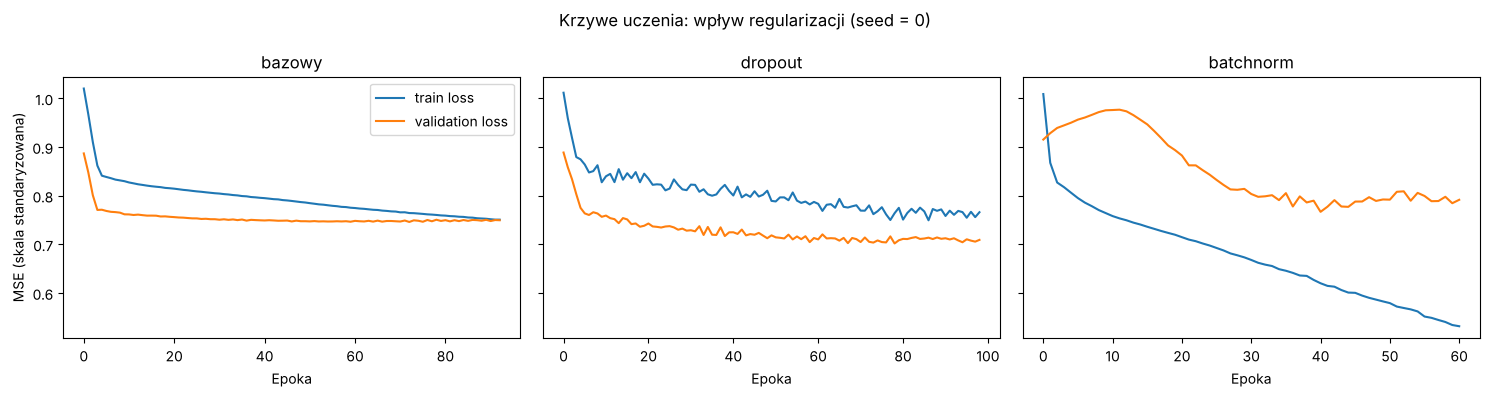

MAE         RMSE          R2       poprawa_vs_naiwny_%      
            mean   std   mean   std  mean   std                mean   std
wariant                                                                  
bazowy     20.71  0.27  26.32  0.23  0.25  0.01               15.01  1.09
dropout    20.55  0.13  26.37  0.19  0.25  0.01               15.67  0.53
batchnorm  21.78  0.52  27.78  0.80  0.16  0.05               10.59  2.14

In [ ]:
# D6: wersja bazowa vs Dropout(0.2) vs BatchNormalization – metryki po 5 ziarnach + krzywe uczenia.
rows, curves = baseline("wariant", "bazowy"), {"bazowy": baseline_hist}
for reg in ["dropout", "batchnorm"]:
    label = reg
    for s in SEEDS:
        r, h = run_experiment("Glucose", feature_cols, regularization=reg, seed=s)
        rows.append({"wariant": label, **r})
        if s == SEEDS[0]:
            curves[label] = h

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (label, h) in zip(axes, curves.items()):
    ax.plot(h.history["loss"], label="train loss")
    ax.plot(h.history["val_loss"], label="validation loss")
    ax.set_title(label)
    ax.set_xlabel("Epoka")
axes[0].set_ylabel("MSE (skala standaryzowana)")
axes[0].legend()
plt.suptitle("Krzywe uczenia: wpływ regularizacji (seed = 0)")
plt.tight_layout()
plt.show()

d6 = summarize(rows, "wariant")
d6

**Komentarz D6.**
- **Dropout(0.2):** MAE podobne (20,55 vs 20,71), ale mniejsza zmienność między ziarnami. Na krzywej strata treningowa
  leży *powyżej* walidacyjnej – to normalne, bo dropout działa tylko w czasie treningu i „utrudnia” zadanie na zbiorze treningowym.
- **BatchNormalization:** wyraźnie gorzej (MAE 21,78, R² 0,16) i największa zmienność. Krzywe pokazują klasyczny overfitting:
  strata treningowa spada do ~0,53, a walidacyjna zatrzymuje się w okolicy 0,8. Początkowy wzrost `val_loss` wynika z tego,
  że w trybie predykcji BN używa średnich kroczących, które w pierwszych epokach są jeszcze nieustabilizowane.
  Przy tak małej sieci i małym zbiorze BN dodaje parametrów i niestabilności zamiast pomagać.
- Wniosek: wersja bazowa **nie miała problemu z overfittingiem** (krzywe w sekcji 5 się nie rozjeżdżają), więc
  regularyzacja nie miała czego naprawiać. Ograniczeniem jest informacja w cechach, nie pojemność modelu.

## 9. Pytania kontrolne – odpowiedzi

**1. Dlaczego X dla Conv1D musi mieć trzy wymiary?**
Keras `Conv1D` przyjmuje tensor `(batch, kroki, kanały)`. Filtr przesuwa się wzdłuż osi *kroków*, a w każdej pozycji
miesza wszystkie *kanały*. Nasza tabela ma tylko dwa wymiary (próbki × cechy), więc dodajemy oś kanału o długości 1:
każda cecha staje się kolejnym krokiem jednokanałowej sekwencji – tak jak próbka sygnału z jednego czujnika.

**2. Czym różni się loss MSE od metryki MAE?**
MSE (średni błąd kwadratowy) jest funkcją, którą optymalizator minimalizuje: jest gładka i różniczkowalna,
mocno karze duże błędy, a jej jednostką jest kwadrat jednostki celu. MAE (średni błąd bezwzględny) służy nam
tylko do raportowania: jest w jednostkach celu (mg/dl) i mniej wrażliwy na pojedyncze duże pomyłki.
RMSE = √MSE wraca do jednostek celu; to, że RMSE > MAE, sygnalizuje obecność dużych błędów.

**3. Dlaczego skalujemy zmienną docelową y w regresji neuronowej?**
Glukoza ma wartości ~40–200 mg/dl, a wyjście sieci po inicjalizacji jest bliskie zera. Bez skalowania początkowe
błędy i gradienty są ogromne, uczenie jest niestabilne, a dobór learning rate staje się zależny od jednostek.
Po standaryzacji cel ma średnią 0 i odchylenie 1, więc ta sama konfiguracja optymalizatora działa przewidywalnie.
Predykcje trzeba potem odwrócić (`inverse_transform`), żeby metryki były w mg/dl.

**4. Dlaczego wartości 0 w niektórych kolumnach Pima mogą oznaczać brak danych?**
Glukoza, ciśnienie krwi, grubość fałdu skórnego, insulina ani BMI żywego człowieka nie mogą wynosić 0 –
to kody braku pomiaru zapisane jako liczba. Gdyby je zostawić, model uczyłby się na fałszywych, skrajnych
wartościach, a średnie i mediany byłyby zaniżone. Inaczej jest z `Pregnancies` – tam 0 to prawdziwa wartość.
W Pima braki są duże: ok. 49% wierszy nie ma insuliny i ok. 30% grubości fałdu skórnego.

**5. Dlaczego Conv1D na danych tabelarycznych wymaga ostrożnej interpretacji?**
Konwolucja zakłada, że sąsiednie pozycje są ze sobą powiązane, a ten sam filtr jest sensowny w każdym miejscu
sekwencji (współdzielenie wag). W tabeli kolejność kolumn jest arbitralna: to, że `Insulin` stoi obok `BMI`,
nie wynika z danych, tylko z pliku CSV. Filtr miesza więc pary cech wybrane przypadkiem, a pooling
uśrednia odpowiedzi z pozycji, które nie są ze sobą porównywalne. Wynik może zależeć od kolejności cech (D5),
a ewentualna przewaga nad Dense nie oznacza, że model „odkrył lokalne wzorce” w danych medycznych.

**6. Co oznacza overfitting na wykresie loss/val_loss?**
Strata treningowa dalej spada, a walidacyjna zatrzymuje się albo zaczyna rosnąć – rozjazd krzywych.
Model zapamiętuje szczegóły zbioru treningowego zamiast uogólniać. `EarlyStopping` z `restore_best_weights=True`
zatrzymuje trening i przywraca wagi z epoki o najniższym `val_loss`.

**7. Kiedy użyłbyś prostego modelu Dense zamiast Conv1D?**
Domyślnie przy danych tabelarycznych, gdzie cechy nie mają naturalnej kolejności ani struktury przestrzennej
czy czasowej, oraz przy małych zbiorach, gdzie dodatkowa złożoność się nie zwraca. Conv1D ma sens dla sekwencji:
szeregów czasowych, sygnałów, widm, tekstu. Przy danych tabelarycznych bardzo mocnym punktem odniesienia
są też modele drzewiaste (Random Forest, Gradient Boosting).